# Test Case 2 — Publication post-processing

Python/Jupyter conversion of `POST_TC2_ADV_DIFF_PUBLICATION_2x4.m`.

This plotting notebook uses the supplied frozen KAPI-ELM publication style
module and keeps the original 2×4 semantics:
three predictor snapshots + residual attention, followed by three corrector
snapshots + collocation enrichment.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

from kapi_onet_publication_style import (
    DOUBLE_COLUMN_WIDTH, BLUE, VERMILLION, GRAY,
    CMAP_MAGNITUDE, add_major_y_grid, format_colorbar, save_figure
)

In [2]:
f1 = Path("STAGE_01_INF_RBF_ADV_DIFF_attention_PAPER.npz")
f2 = Path("STAGE_02_INF_RBF_ADV_DIFF_results_PAPER.npz")
if not f1.exists():
    raise FileNotFoundError("Run STAGE_01_INF_RBF_ADV_DIFF_PAPER.ipynb first.")
if not f2.exists():
    raise FileNotFoundError("Run STAGE_02_INF_RBF_ADV_DIFF_PAPER.ipynb first.")

P = np.load(f1, allow_pickle=False)
C = np.load(f2, allow_pickle=False)

tol = 1e-14
if abs(float(P["a"]) - float(C["a"])) > tol or abs(float(P["nu"]) - float(C["nu"])) > tol:
    raise ValueError("Predictor/corrector PDE parameters do not match.")
if abs(float(P["sigma_x"]) - float(C["sigma_x"])) > tol or abs(float(P["sigma_t"]) - float(C["sigma_t"])) > tol:
    raise ValueError("Predictor/corrector kernel scales do not match.")
if int(P["NBx"]) != int(C["NBx"]) or int(P["nSlabs"]) != int(C["nSlabs"]):
    raise ValueError("Predictor/corrector discretizations do not match.")

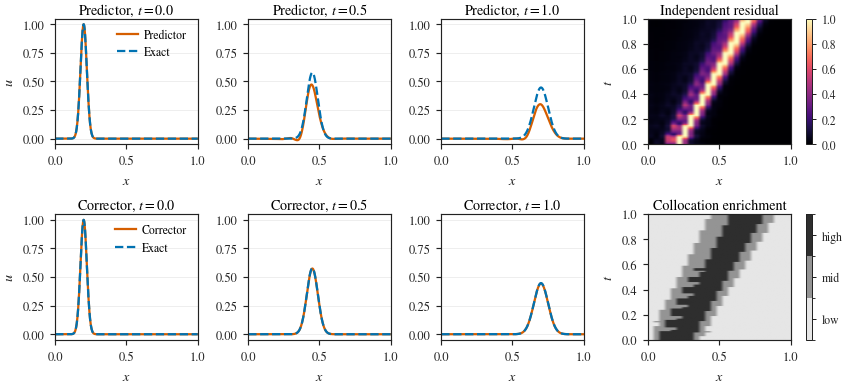

Saved:
  TC2_AdvDiff_2x4.pdf
  TC2_AdvDiff_2x4.png


In [3]:
XL, XR = float(P["XL"]), float(P["XR"])
a, nu = float(P["a"]), float(P["nu"])
x = P["x_plot"]
t_snap = np.array([0.00, 0.50, 1.00])

def uexact(xx, tt):
    return (1.0 / np.sqrt(4*tt + 1)) * np.exp(-((xx - 0.2 - a*tt)**2) / (nu*(4*tt + 1)))

idxP = np.array([np.argmin(np.abs(P["plot_times"] - t)) for t in t_snap])
idxC = np.array([np.argmin(np.abs(C["plot_times"] - t)) for t in t_snap])
t_used = P["plot_times"][idxP]

U_pred_snap = P["Uplot"][idxP].T
U_corr_snap = C["Uplot"][idxC].T
U_ex_snap = np.column_stack([uexact(x, t) for t in t_used])

Rmat = P["attention_score_mat"]
Lmat = P["Lmat"]
x_edges = P["x_edges"]
nSlabs = int(P["nSlabs"])
dt_slab = float(P["dt_slab"])

# Original MATLAB plotting uses 2x4 panels.  Final printed width is inherited
# from the publication template.
fig, axes = plt.subplots(
    2, 4,
    figsize=(DOUBLE_COLUMN_WIDTH, DOUBLE_COLUMN_WIDTH * 0.46),
    constrained_layout=True
)

# Top row: predictor snapshots
for k in range(3):
    ax = axes[0, k]
    ax.plot(x, U_pred_snap[:, k], color=VERMILLION, label="Predictor")
    ax.plot(x, U_ex_snap[:, k], "--", color=BLUE, label="Exact")
    ax.set_xlim(XL, XR)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r"$x$")
    if k == 0:
        ax.set_ylabel(r"$u$")
        ax.legend(loc="upper right")
    ax.set_title(rf"Predictor, $t={t_used[k]:.1f}$")
    add_major_y_grid(ax)

# Independent residual attention heatmap
ax = axes[0, 3]
im = ax.imshow(
    Rmat, origin="lower", aspect="auto",
    extent=[x_edges[0], x_edges[-1], 0, nSlabs*dt_slab],
    vmin=0, vmax=1, cmap=CMAP_MAGNITUDE
)
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$t$")
ax.set_title("Independent residual")
cb = fig.colorbar(im, ax=ax)
format_colorbar(cb)

# Bottom row: corrector snapshots
for k in range(3):
    ax = axes[1, k]
    ax.plot(x, U_corr_snap[:, k], color=VERMILLION, label="Corrector")
    ax.plot(x, U_ex_snap[:, k], "--", color=BLUE, label="Exact")
    ax.set_xlim(XL, XR)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r"$x$")
    if k == 0:
        ax.set_ylabel(r"$u$")
        ax.legend(loc="upper right")
    ax.set_title(rf"Corrector, $t={t_used[k]:.1f}$")
    add_major_y_grid(ax)

# Collocation enrichment
ax = axes[1, 3]
level_cmap = ListedColormap(["#E6E6E6", "#949494", "#2E2E2E"])
level_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], level_cmap.N)
im2 = ax.imshow(
    Lmat, origin="lower", aspect="auto",
    extent=[x_edges[0], x_edges[-1], 0, nSlabs*dt_slab],
    cmap=level_cmap, norm=level_norm
)
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$t$")
ax.set_title("Collocation enrichment")
cb2 = fig.colorbar(im2, ax=ax, ticks=[1, 2, 3])
cb2.ax.set_yticklabels(["low", "mid", "high"])
format_colorbar(cb2)

saved = save_figure(fig, "TC2_AdvDiff_2x4", formats=("pdf", "png"))
plt.show()
print("Saved:", *saved, sep="\n  ")

In [4]:
# Joint-table CSV row
row = {
    "Case": "Advection-diffusion",
    "Equation": "u_t + a u_x - nu u_xx = 0",
    "Parameter": f"a={float(P['a']):.2f}, nu={float(P['nu']):.0e}",
    "Predictor_PDE": int(P["Npde"]),
    "Predictor_RMSE": float(P["predictor_rmse"]),
    "Predictor_MaxError": float(P["predictor_max_error"]),
    "Corrector_AvgPDE": float(C["avg_Npde"]),
    "Corrector_MinPDE": int(C["min_Npde"]),
    "Corrector_MaxPDE": int(C["max_Npde"]),
    "Corrector_RMSE": float(C["corrector_rmse"]),
    "Corrector_MaxError": float(C["corrector_max_error"]),
    "RMSE_Improvement": float(P["predictor_rmse"]) / float(C["corrector_rmse"]),
    "MaxError_Improvement": float(P["predictor_max_error"]) / float(C["corrector_max_error"]),
    "Sigma_x": float(P["sigma_x"]),
    "Sigma_t": float(P["sigma_t"]),
    "Pilot_PointsPerBlock": int(P["Npde_per_block_pilot"]),
    "Low_PointsPerBlock": int(C["Npde_level"][0]),
    "Mid_PointsPerBlock": int(C["Npde_level"][1]),
    "High_PointsPerBlock": int(C["Npde_level"][2]),
}

T = pd.DataFrame([row])
T.to_csv("TC2_AdvDiff_Table.csv", index=False)
display(T)

print(f"Predictor RMSE = {row['Predictor_RMSE']:.6e}")
print(f"Corrector RMSE = {row['Corrector_RMSE']:.6e}")
print(f"Avg PDE points = {row['Corrector_AvgPDE']:.2f}")
print(f"RMSE gain      = {row['RMSE_Improvement']:.3f} x")

,Case,Equation,Parameter,Predictor_PDE,Predictor_RMSE,Predictor_MaxError,Corrector_AvgPDE,Corrector_MinPDE,Corrector_MaxPDE,Corrector_RMSE,Corrector_MaxError,RMSE_Improvement,MaxError_Improvement,Sigma_x,Sigma_t,Pilot_PointsPerBlock,Low_PointsPerBlock,Mid_PointsPerBlock,High_PointsPerBlock
0,Advection-diffusion,u_t + a u_x - nu u_xx = 0,"a=0.50, nu=1e-03",100,0.043597,0.150471,326.16,304,344,0.000942,0.00346,46.264592,43.491003,0.02,0.01,4,8,16,24


Predictor RMSE = 4.359714e-02
Corrector RMSE = 9.423435e-04
Avg PDE points = 326.16
RMSE gain      = 46.265 x
